# StyleBot Preparación común de datos

    Este notebook prepara la parte del líder para la primera entrega: cargar Fashion-MNIST, separar datos, comprobar categorías y generar evidencia para el equipo. No entrena clasificadores.

    **Responsable:** Krysto Alberto Adan Jauregui Zuñiga.

    **Cómo usarlo:** abre el archivo en Google Colab y ejecuta las celdas de arriba hacia abajo. Para este trabajo basta el entorno normal de CPU. Conserva una copia en tu Google Drive. La primera ejecución necesita conexión a Internet para descargar el dataset.

    **Estado del archivo:** es una plantilla lista para ejecutar, con salidas vacías. Las comprobaciones que aparecen al ejecutarlo corresponden a tu propia sesión. Lee y explica el código; cita las fuentes y reconoce la asistencia utilizada según las reglas de tu curso.

## 1 Carga común para todo el equipo

    Esta celda define las categorías y las funciones. Todos deben conservarla igual. `X` contiene imágenes y `y` las categorías correctas.

    La prueba oficial tiene 10,000 imágenes. De las otras 60,000 apartamos 20 % para validación: quedan 48,000 para entrenamiento y 12,000 para validación. `stratify` conserva la proporción de las categorías y la semilla 42 fija la división. Los píxeles ya quedan normalizados entre 0 y 1; no vuelvas a dividirlos entre 255.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


## 2 Descargar y preparar Fashion MNIST

    Ejecuta la siguiente celda. `fashion_mnist.load_data()` descarga automáticamente los archivos oficiales a través de TensorFlow/Keras.

    Esperamos estas formas: entrenamiento `(48000, 28, 28)`, validación `(12000, 28, 28)` y prueba `(10000, 28, 28)`. La descarga puede tardar la primera vez.

In [ ]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


## 3 Comprobar la división y los valores

    Las instrucciones `assert` detienen la ejecución si algo no coincide con lo esperado. Conservamos los índices de entrenamiento y validación para verificar que no se mezclaron. Los índices de prueba pertenecen a un archivo diferente.

    Revisamos forma, cantidad, rango, valores no finitos y categorías. Esto no equivale a una inspección exhaustiva de daños visuales ni a una búsqueda de duplicados de contenido.

In [ ]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


## 4 Ver las categorías y sus cantidades

    Los números tienen el mismo significado para todos los integrantes. Camiseta es 0 y camisa es 6; no deben intercambiarse. Con esta división esperamos 4,800 imágenes de entrenamiento, 1,200 de validación y 1,000 de prueba por categoría.

In [ ]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")


ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


## 5 Guardar las tablas y las reglas del equipo

    Se guardan categorías, conteos, comprobaciones, índices y un protocolo con la semilla, las versiones y las huellas de la división. El archivo de índices es pequeño: no contiene las imágenes.

    Si dos integrantes usan diferentes versiones, comparen las huellas en `protocolo_datos.json`. Si no coinciden, acuerden una misma versión o reutilicen los índices del líder antes de comparar modelos.

In [ ]:
from pathlib import Path
import csv
import hashlib
import importlib.metadata
import json
import zipfile

# Todos los resultados se escriben en esta carpeta, dentro de la sesión actual.
CARPETA_SALIDA = Path("StyleBot_datos_generados")
for subcarpeta in ["datos", "resultados/tablas", "resultados/graficas"]:
    (CARPETA_SALIDA / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_csv(ruta, filas):
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

guardar_csv(CARPETA_SALIDA / "datos/categorias.csv", [
    {"id": i, "categoria": nombre} for i, nombre in enumerate(CATEGORIAS)
])
guardar_csv(CARPETA_SALIDA / "resultados/tablas/conteo_clases.csv", conteo_clases)
guardar_csv(CARPETA_SALIDA / "resultados/tablas/verificacion_datos.csv", comprobaciones)

np.savez_compressed(
    CARPETA_SALIDA / "datos/particiones_semilla42.npz",
    idx_train=datos["idx_train"], idx_val=datos["idx_val"], idx_test=datos["idx_test"]
)

versiones = {}
for paquete in ["numpy", "scikit-learn", "matplotlib", "tensorflow"]:
    try:
        versiones[paquete] = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        versiones[paquete] = "no detectado en este entorno"

huellas_indices = {
    nombre: hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    for nombre in ["idx_train", "idx_val", "idx_test"]
}
protocolo = {
    "dataset": "Fashion-MNIST", "semilla": SEMILLA,
    "entrenamiento": 48000, "validacion": 12000, "prueba": 10000,
    "origen_train_val": "60,000 imágenes oficiales de entrenamiento",
    "origen_test": "10,000 imágenes oficiales de prueba, conservadas",
    "separacion": "train_test_split, test_size=0.20, stratify=y_base",
    "forma_imagen": [28, 28], "normalizacion": "float32 / 255.0, una sola vez",
    "categorias": {str(i): nombre for i, nombre in enumerate(CATEGORIAS)},
    "sha256_indices": huellas_indices, "versiones": versiones,
}
(CARPETA_SALIDA / "datos/protocolo_datos.json").write_text(
    json.dumps(protocolo, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados guardados en:", CARPETA_SALIDA.resolve())
print("Huella de la división de entrenamiento:", huellas_indices["idx_train"])


Resultados guardados en: /content/StyleBot_datos_generados
Huella de la división de entrenamiento: 1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9


## 6 Mostrar ejemplos y distribución

    Estas figuras sirven para revisar que las categorías y sus imágenes tengan sentido. La selección de ejemplos utiliza únicamente entrenamiento.

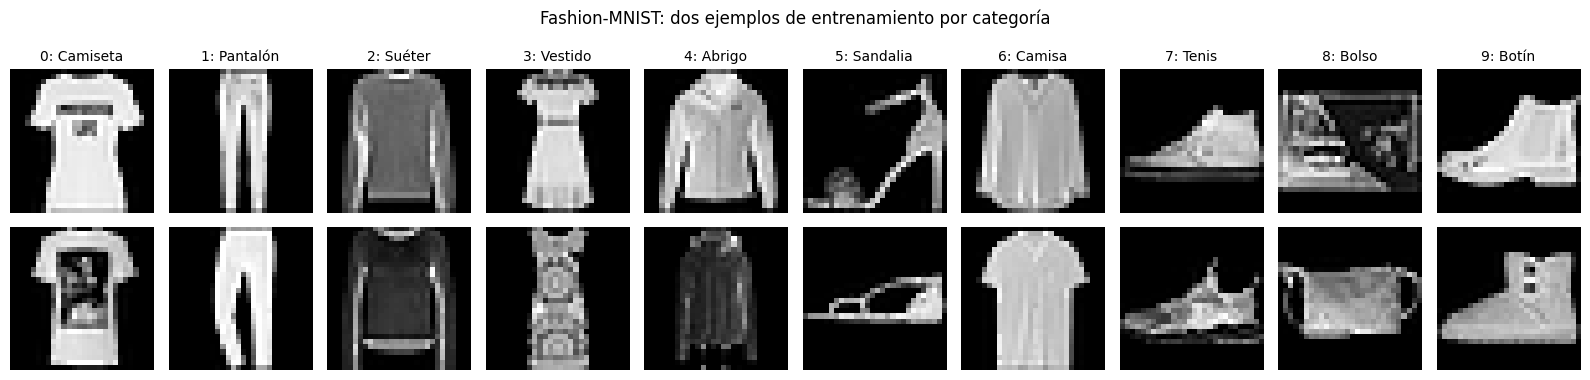

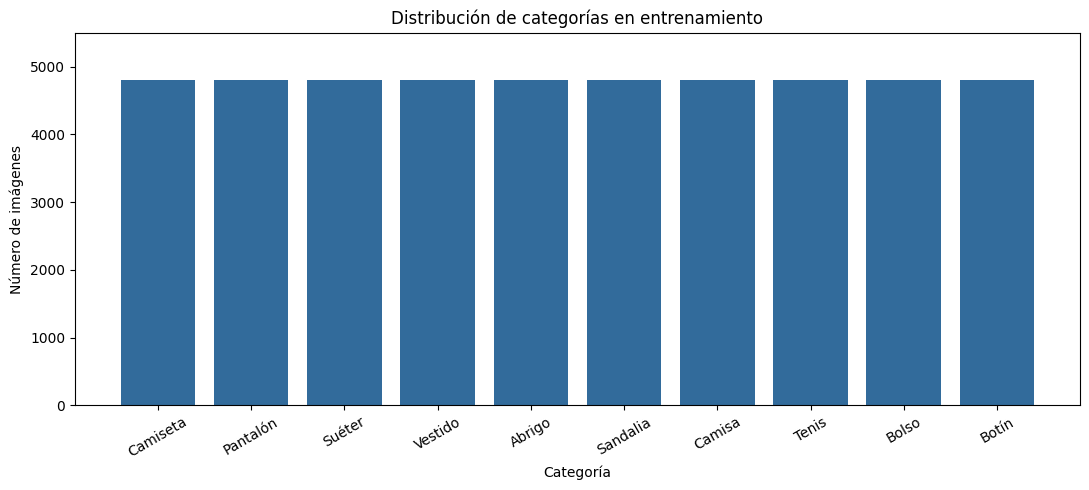

In [ ]:
import matplotlib.pyplot as plt

# Solo usamos entrenamiento para elegir los ejemplos exploratorios.
fig, ejes = plt.subplots(2, 10, figsize=(16, 4))
for categoria_id, nombre in enumerate(CATEGORIAS):
    ejemplos = np.flatnonzero(y_train == categoria_id)[:2]
    for fila, indice in enumerate(ejemplos):
        ejes[fila, categoria_id].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[fila, categoria_id].axis("off")
        if fila == 0:
            ejes[fila, categoria_id].set_title(f"{categoria_id}: {nombre}", fontsize=10)
fig.suptitle("Fashion-MNIST: dos ejemplos de entrenamiento por categoría")
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/ejemplos_prendas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(CATEGORIAS, np.bincount(y_train, minlength=10), color="#326b9b")
ax.set_title("Distribución de categorías en entrenamiento")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 5500)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/distribucion_entrenamiento.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


## 7 Descargar los resultados para el equipo

    La siguiente celda descarga un ZIP con las tablas, figuras y protocolo. Guárdalo en tu computadora y extráelo antes de subir los archivos a GitHub.

    Además, descarga este notebook desde Archivo y Descargar como `.ipynb` después de ejecutarlo. Ese archivo conservará las salidas de tu sesión. El ZIP de resultados no incluye automáticamente el notebook.

In [ ]:
ruta_zip = Path("StyleBot_datos_generados.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_SALIDA.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_SALIDA))
print("Archivo preparado:", ruta_zip.resolve())

# En Colab, esta línea ofrece el ZIP para descargar a tu computadora.
try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))


Archivo preparado: /content/StyleBot_datos_generados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8 Revisar y entregar

    - Comprueba que no haya errores y que las categorías coincidan con las imágenes.
    - Escribe tu nombre y una explicación con tus propias palabras.
    - Sube el notebook ejecutado, `categorias.csv`, `particiones_semilla42.npz`, `protocolo_datos.json`, tablas y gráficas.
    - Comparte el enlace del notebook y el protocolo con los cuatro compañeros.
    - Cada compañero puede abrir el notebook, guardar una copia con el nombre de su parte y conservar las celdas comunes de carga.
    - El conjunto de prueba se reserva para la evaluación final; no se usa para seleccionar parámetros, ajustar PCA o entrenar modelos.

    **Para el informe:** después de ejecutar, describe las cantidades observadas, el tipo de datos, la normalización y las comprobaciones realizadas. No afirmes que eliminaste imágenes dañadas o duplicadas si no hiciste esa revisión.

    **Fuentes**

    - TensorFlow. Fashion-MNIST load_data. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
    - TensorFlow. Basic classification. https://www.tensorflow.org/tutorials/keras/classification
    - Scikit-learn. train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
    - Zalando Research. Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist

In [ ]:
!pip -q install scikit-image

Entrenamiento: (48000, 784)
Validación: (12000, 784)
Prueba: (10000, 784)

RESULTADO PRELIMINAR


,modelo,representacion,muestra_entrenamiento,accuracy_validacion,tiempo_entrenamiento_segundos,estado
0,Regresión logística,Píxeles crudos,5000,0.802083,19.40925,PRELIMINAR


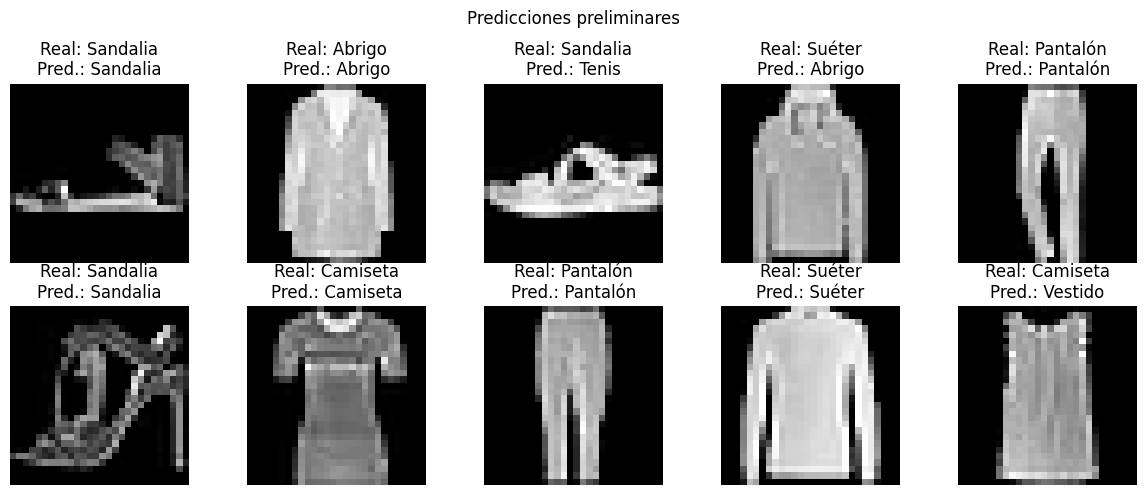


PCA terminado en 2.4 segundos.
Varianza explicada: 91.19%

Entrenando: Regresión logística con Píxeles crudos


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Entrenando: Regresión logística con PCA (100 componentes)

Entrenando: SVM lineal con Píxeles crudos

Entrenando: SVM lineal con PCA (100 componentes)

Entrenando: Random Forest con Píxeles crudos

Entrenando: Random Forest con PCA (100 componentes)

TABLA COMPARATIVA PRELIMINAR


,modelo,representacion,accuracy_validacion,precision_ponderada,recall_ponderado,f1_ponderado,tiempo_entrenamiento_segundos,estado
0,Random Forest,Píxeles crudos,0.884167,0.883595,0.884167,0.883142,74.611818,PRELIMINAR
1,Random Forest,PCA (100 componentes),0.874167,0.873397,0.874167,0.872784,86.704143,PRELIMINAR
2,Regresión logística,PCA (100 componentes),0.857333,0.856236,0.857333,0.856560,4.757745,PRELIMINAR
3,SVM lineal,Píxeles crudos,0.856083,0.854332,0.856083,0.854544,207.440293,PRELIMINAR
4,Regresión logística,Píxeles crudos,0.850667,0.849627,0.850667,0.850053,95.581152,PRELIMINAR
5,SVM lineal,PCA (100 componentes),0.850667,0.848661,0.850667,0.848699,9.847629,PRELIMINAR



Mejores representaciones:
{'Random Forest': 'Píxeles crudos', 'Regresión logística': 'PCA (100 componentes)', 'SVM lineal': 'Píxeles crudos'}

Ajustando Regresión logística con PCA (100 componentes)...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Ajustando SVM lineal con Píxeles crudos...
Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [ ]:
# ============================================================
# CLASIFICACIÓN DE FASHION-MNIST — CÓDIGO CORREGIDO
# ============================================================

import time
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from skimage.feature import hog
from skimage.measure import moments_central, moments_normalized, moments_hu


# ------------------------------------------------------------
# 0. Configuración
# ------------------------------------------------------------

SEMILLA = 42
N_COMPONENTES_PCA = 100
TAMANO_CV = 12000

np.random.seed(SEMILLA)

assert "X_train" in globals(), "Ejecuta primero las celdas de preparación de datos."
assert X_train.shape[0] == 48000
assert X_val.shape[0] == 12000
assert X_test.shape[0] == 10000

if "CATEGORIAS" not in globals():
    CATEGORIAS = [
        "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
        "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
    ]

CARPETA = Path("StyleBot_modelos_resultados")
(CARPETA / "matrices_confusion").mkdir(parents=True, exist_ok=True)
(CARPETA / "errores").mkdir(parents=True, exist_ok=True)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Entrenamiento:", X_train_flat.shape)
print("Validación:", X_val_flat.shape)
print("Prueba:", X_test_flat.shape)


# ------------------------------------------------------------
# 1. Clasificador preliminar con 5,000 imágenes
# ------------------------------------------------------------

idx_pequena, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=5000,
    stratify=y_train,
    random_state=SEMILLA,
)

modelo_preliminar = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        max_iter=500,
        random_state=SEMILLA,
    )),
])

inicio = time.perf_counter()
modelo_preliminar.fit(X_train_flat[idx_pequena], y_train[idx_pequena])
tiempo_preliminar = time.perf_counter() - inicio

pred_preliminar = modelo_preliminar.predict(X_val_flat)

tabla_preliminar = pd.DataFrame([{
    "modelo": "Regresión logística",
    "representacion": "Píxeles crudos",
    "muestra_entrenamiento": 5000,
    "accuracy_validacion": accuracy_score(y_val, pred_preliminar),
    "tiempo_entrenamiento_segundos": tiempo_preliminar,
    "estado": "PRELIMINAR",
}])

print("\nRESULTADO PRELIMINAR")
display(tabla_preliminar)

tabla_preliminar.to_csv(
    CARPETA / "tabla_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

fig, ejes = plt.subplots(2, 5, figsize=(12, 5))

for eje, indice in zip(ejes.ravel(), range(10)):
    eje.imshow(X_val[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_val[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_preliminar[indice]]}"
    )
    eje.axis("off")

fig.suptitle("Predicciones preliminares")
fig.tight_layout()
fig.savefig(CARPETA / "predicciones_preliminares.png", dpi=160)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 2. PCA
# ------------------------------------------------------------

pca_base = PCA(
    n_components=N_COMPONENTES_PCA,
    svd_solver="randomized",
    random_state=SEMILLA,
)

inicio = time.perf_counter()

X_train_pca = pca_base.fit_transform(X_train_flat)
X_val_pca = pca_base.transform(X_val_flat)
X_test_pca = pca_base.transform(X_test_flat)

print(
    f"\nPCA terminado en {time.perf_counter() - inicio:.1f} segundos."
)
print(
    f"Varianza explicada: "
    f"{pca_base.explained_variance_ratio_.sum():.2%}"
)


# ------------------------------------------------------------
# 3. Modelos base: logística, SVM lineal y Random Forest
# ------------------------------------------------------------

def crear_modelo_base(nombre):
    if nombre == "Regresión logística":
        return LogisticRegression(
            C=1.0,
            max_iter=500,
            random_state=SEMILLA,
        )

    if nombre == "SVM lineal":
        # CONFIGURACIÓN CORREGIDA: más rápida que la anterior.
        return LinearSVC(
            C=0.1,
            dual=False,
            tol=1e-3,
            max_iter=1500,
            random_state=SEMILLA,
        )

    if nombre == "Random Forest":
        return RandomForestClassifier(
            n_estimators=150,
            max_depth=None,
            n_jobs=-1,
            random_state=SEMILLA,
        )

    raise ValueError(f"Modelo no reconocido: {nombre}")


def crear_pipeline_base(nombre):
    modelo = crear_modelo_base(nombre)

    if nombre in ["Regresión logística", "SVM lineal"]:
        return Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", modelo),
        ])

    return Pipeline([
        ("modelo", modelo),
    ])


representaciones = {
    "Píxeles crudos": (X_train_flat, X_val_flat),
    "PCA (100 componentes)": (X_train_pca, X_val_pca),
}

nombres_modelos = [
    "Regresión logística",
    "SVM lineal",
    "Random Forest",
]

filas_base = []

for nombre_modelo in nombres_modelos:
    for nombre_representacion, (X_entrena, X_valida) in representaciones.items():
        print(f"\nEntrenando: {nombre_modelo} con {nombre_representacion}")

        modelo = crear_pipeline_base(nombre_modelo)

        inicio = time.perf_counter()
        modelo.fit(X_entrena, y_train)
        segundos = time.perf_counter() - inicio

        pred = modelo.predict(X_valida)

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_val,
            pred,
            average="weighted",
            zero_division=0,
        )

        filas_base.append({
            "modelo": nombre_modelo,
            "representacion": nombre_representacion,
            "accuracy_validacion": accuracy_score(y_val, pred),
            "precision_ponderada": precision,
            "recall_ponderado": recall,
            "f1_ponderado": f1,
            "tiempo_entrenamiento_segundos": segundos,
            "estado": "PRELIMINAR",
        })

tabla_base = pd.DataFrame(filas_base).sort_values(
    "f1_ponderado",
    ascending=False,
).reset_index(drop=True)

print("\nTABLA COMPARATIVA PRELIMINAR")
display(tabla_base)

tabla_base.to_csv(
    CARPETA / "tabla_comparativa_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

mejores_representaciones = (
    tabla_base.loc[
        tabla_base.groupby("modelo")["f1_ponderado"].idxmax(),
        ["modelo", "representacion"],
    ]
    .set_index("modelo")["representacion"]
    .to_dict()
)

print("\nMejores representaciones:")
print(mejores_representaciones)


# ------------------------------------------------------------
# 4. Validación cruzada y ajuste de parámetros
# ------------------------------------------------------------

idx_cv, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TAMANO_CV,
    stratify=y_train,
    random_state=SEMILLA,
)

X_cv = X_train_flat[idx_cv]
y_cv = y_train[idx_cv]

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEMILLA,
)


def crear_pipeline_ajuste(nombre_modelo, representacion):
    pasos = []

    if representacion == "PCA (100 componentes)":
        pasos.append((
            "pca",
            PCA(
                n_components=N_COMPONENTES_PCA,
                svd_solver="randomized",
                random_state=SEMILLA,
            ),
        ))

    if nombre_modelo == "Regresión logística":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", LogisticRegression(
                max_iter=500,
                random_state=SEMILLA,
            )),
        ])

    elif nombre_modelo == "SVM lineal":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", LinearSVC(
                dual=False,
                tol=1e-3,
                max_iter=1500,
                random_state=SEMILLA,
            )),
        ])

    elif nombre_modelo == "Random Forest":
        pasos.append((
            "modelo",
            RandomForestClassifier(
                n_jobs=-1,
                random_state=SEMILLA,
            ),
        ))

    return Pipeline(pasos)


parametros_por_modelo = {
    "Regresión logística": {
        "modelo__C": [0.1, 1.0, 10.0],
    },
    "SVM lineal": {
        "modelo__C": [0.01, 0.1, 1.0],
    },
    "Random Forest": {
        "modelo__n_estimators": [100, 150],
        "modelo__max_depth": [None, 25],
    },
}

modelos_ajustados = {}
filas_ajuste = []

for nombre_modelo in nombres_modelos:
    representacion = mejores_representaciones[nombre_modelo]

    print(
        f"\nAjustando {nombre_modelo} "
        f"con {representacion}..."
    )

    pipeline = crear_pipeline_ajuste(nombre_modelo, representacion)

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros_por_modelo[nombre_modelo],
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
    )

    inicio = time.perf_counter()
    busqueda.fit(X_cv, y_cv)
    segundos_cv = time.perf_counter() - inicio

    modelo_ajustado = clone(busqueda.best_estimator_)
    modelo_ajustado.fit(X_train_flat, y_train)

    pred_val = modelo_ajustado.predict(X_val_flat)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        pred_val,
        average="weighted",
        zero_division=0,
    )

    nombre_candidato = f"{nombre_modelo} ({representacion})"
    modelos_ajustados[nombre_candidato] = modelo_ajustado

    filas_ajuste.append({
        "candidato": nombre_candidato,
        "modelo": nombre_modelo,
        "representacion": representacion,
        "mejores_parametros": json.dumps(busqueda.best_params_),
        "f1_cv_promedio": busqueda.best_score_,
        "accuracy_validacion": accuracy_score(y_val, pred_val),
        "precision_ponderada_validacion": precision,
        "recall_ponderado_validacion": recall,
        "f1_ponderado_validacion": f1,
        "tiempo_ajuste_cv_segundos": segundos_cv,
    })


# ------------------------------------------------------------
# 5. Regresión logística con HOG + momentos de Hu
# ------------------------------------------------------------

def extraer_hog_hu(imagenes, nombre):
    caracteristicas = []

    for i, imagen in enumerate(imagenes):
        caracteristicas_hog = hog(
            imagen,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
        )

        momentos = moments_central(imagen)
        momentos_normalizados = moments_normalized(momentos)
        hu = moments_hu(momentos_normalizados)

        hu = np.sign(hu) * np.log1p(np.abs(hu))

        caracteristicas.append(
            np.concatenate([caracteristicas_hog, hu])
        )

        if (i + 1) % 5000 == 0:
            print(f"{nombre}: {i + 1}/{len(imagenes)}")

    return np.asarray(caracteristicas, dtype=np.float32)


print("\nExtrayendo HOG + Hu...")
X_train_hog_hu = extraer_hog_hu(X_train, "Entrenamiento")
X_val_hog_hu = extraer_hog_hu(X_val, "Validación")

pipeline_hog_hu = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=700,
        random_state=SEMILLA,
    )),
])

busqueda_hog_hu = GridSearchCV(
    estimator=pipeline_hog_hu,
    param_grid={"modelo__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
)

inicio = time.perf_counter()
busqueda_hog_hu.fit(X_train_hog_hu[idx_cv], y_train[idx_cv])
segundos_hog_hu = time.perf_counter() - inicio

modelo_hog_hu = clone(busqueda_hog_hu.best_estimator_)
modelo_hog_hu.fit(X_train_hog_hu, y_train)

pred_val_hog_hu = modelo_hog_hu.predict(X_val_hog_hu)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_val,
    pred_val_hog_hu,
    average="weighted",
    zero_division=0,
)

nombre_hog_hu = "Regresión logística (HOG + Hu)"
modelos_ajustados[nombre_hog_hu] = modelo_hog_hu

filas_ajuste.append({
    "candidato": nombre_hog_hu,
    "modelo": "Regresión logística",
    "representacion": "HOG + momentos de Hu",
    "mejores_parametros": json.dumps(busqueda_hog_hu.best_params_),
    "f1_cv_promedio": busqueda_hog_hu.best_score_,
    "accuracy_validacion": accuracy_score(y_val, pred_val_hog_hu),
    "precision_ponderada_validacion": precision,
    "recall_ponderado_validacion": recall,
    "f1_ponderado_validacion": f1,
    "tiempo_ajuste_cv_segundos": segundos_hog_hu,
})

tabla_ajuste = pd.DataFrame(filas_ajuste).sort_values(
    "f1_ponderado_validacion",
    ascending=False,
).reset_index(drop=True)

print("\nRESULTADOS DEL AJUSTE")
display(tabla_ajuste)

tabla_ajuste.to_csv(
    CARPETA / "tabla_ajuste_validacion_cruzada.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 6. Evaluación final y matrices de confusión
# ------------------------------------------------------------

print("\nExtrayendo HOG + Hu para prueba...")
X_test_hog_hu = extraer_hog_hu(X_test, "Prueba")

filas_finales = []
predicciones_finales = {}

for nombre_candidato, modelo in modelos_ajustados.items():
    print(f"\nEvaluando: {nombre_candidato}")

    if nombre_candidato == nombre_hog_hu:
        X_entrada_prueba = X_test_hog_hu
    else:
        X_entrada_prueba = X_test_flat

    pred_prueba = modelo.predict(X_entrada_prueba)
    predicciones_finales[nombre_candidato] = pred_prueba

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        pred_prueba,
        average="weighted",
        zero_division=0,
    )

    filas_finales.append({
        "candidato": nombre_candidato,
        "accuracy_prueba": accuracy_score(y_test, pred_prueba),
        "precision_ponderada_prueba": precision,
        "recall_ponderado_prueba": recall,
        "f1_ponderado_prueba": f1,
    })

    matriz = confusion_matrix(y_test, pred_prueba)

    fig, eje = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CATEGORIAS,
    ).plot(
        ax=eje,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
    )

    eje.set_title(f"Matriz de confusión: {nombre_candidato}")
    fig.tight_layout()

    nombre_archivo = (
        nombre_candidato
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("+", "mas")
    )

    fig.savefig(
        CARPETA / "matrices_confusion" / f"{nombre_archivo}.png",
        dpi=180,
    )

    plt.show()
    plt.close(fig)

tabla_final = pd.DataFrame(filas_finales).sort_values(
    "f1_ponderado_prueba",
    ascending=False,
).reset_index(drop=True)

print("\nMÉTRICAS FINALES")
display(tabla_final)

tabla_final.to_csv(
    CARPETA / "metricas_finales_prueba.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 7. Ejemplos de errores del mejor modelo de validación
# ------------------------------------------------------------

modelo_elegido = tabla_ajuste.iloc[0]["candidato"]
pred_elegido = predicciones_finales[modelo_elegido]

errores = np.flatnonzero(pred_elegido != y_test)

print(f"\nModelo elegido: {modelo_elegido}")
print(f"Errores en prueba: {len(errores)}")

rng = np.random.default_rng(SEMILLA)
ejemplos_error = rng.choice(
    errores,
    size=min(20, len(errores)),
    replace=False,
)

fig, ejes = plt.subplots(4, 5, figsize=(13, 10))

for eje, indice in zip(ejes.ravel(), ejemplos_error):
    eje.imshow(X_test[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_test[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_elegido[indice]]}"
    )
    eje.axis("off")

fig.suptitle(f"Ejemplos de errores: {modelo_elegido}")
fig.tight_layout()
fig.savefig(
    CARPETA / "errores" / "ejemplos_de_errores.png",
    dpi=180,
)
plt.show()
plt.close(fig)

reporte = classification_report(
    y_test,
    pred_elegido,
    target_names=CATEGORIAS,
    zero_division=0,
)

print("\nREPORTE DEL MODELO ELEGIDO")
print(reporte)

(CARPETA / "reporte_clasificacion_modelo_elegido.txt").write_text(
    reporte,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 8. README y ZIP final
# ------------------------------------------------------------

mejor_fila = tabla_final.iloc[0]

readme = f"""# Resultados Fashion-MNIST

## Modelo elegido por validación
{modelo_elegido}

## División de datos
- Entrenamiento: 48,000 imágenes.
- Validación: 12,000 imágenes.
- Prueba: 10,000 imágenes.
- Semilla: {SEMILLA}.

## Modelos comparados
- Regresión logística.
- SVM lineal.
- Random Forest.
- Regresión logística con HOG y momentos de Hu.

Se compararon píxeles crudos y PCA. Los hiperparámetros
se ajustaron con validación cruzada estratificada.

## Mejor resultado de prueba
- Candidato: {mejor_fila["candidato"]}
- Accuracy: {mejor_fila["accuracy_prueba"]:.4f}
- Precision ponderada: {mejor_fila["precision_ponderada_prueba"]:.4f}
- Recall ponderado: {mejor_fila["recall_ponderado_prueba"]:.4f}
- F1 ponderado: {mejor_fila["f1_ponderado_prueba"]:.4f}

## Fuentes
- https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
- https://scikit-learn.org/stable/
- https://scikit-image.org/docs/stable/
"""

(CARPETA / "README_resultados.md").write_text(
    readme,
    encoding="utf-8",
)

ruta_zip = Path("StyleBot_modelos_resultados.zip")

with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for archivo in CARPETA.rglob("*"):
        if archivo.is_file():
            comprimido.write(
                archivo,
                archivo.relative_to(CARPETA),
            )

print("\n" + "=" * 60)
print("TERMINADO")
print("Carpeta:", CARPETA.resolve())
print("ZIP:", ruta_zip.resolve())
print("=" * 60)